# 12 - Policy Evaluation

**Purpose:** Compare "email everyone", "email no one", and model-targeted policies using realized outcomes on the held-out randomized test set, and show how the comparison changes with the cost of an email.

**Inputs:** `../data/train.parquet`, `../data/test.parquet`, `../models/winning_uplift_model.pkl`.

**Outputs:** Policy comparison table, bootstrap interval at $0.10 per email, and a cost-sensitivity table.


**Assumptions.** The cost per email is $0.10 (a stated assumption, not a real company figure). The value of an incremental visit is the mean spend per visitor in the treatment arm of the training split. A customer is emailed when predicted uplift times value per visit exceeds the cost. The model only selects customers; every policy is scored with realized outcomes on the test set. The test set is a randomized experiment, so within any group of customers the treated-minus-control difference in visit rate estimates what emailing that group achieved.

In [1]:
# ==========================================
# Load Partitions and Uplift Model
# ==========================================
import warnings
warnings.filterwarnings('ignore', message='Function stable_cumsum is deprecated')
import numpy as np
import pandas as pd
import joblib

train_df = pd.read_parquet('../data/train.parquet')
test_df = pd.read_parquet('../data/test.parquet')
feature_cols = [c for c in train_df.columns if c not in ['visit', 'treatment_flag', 'spend']]

y_train, t_train, spend_train = train_df['visit'], train_df['treatment_flag'], train_df['spend']
X_test, y_test, t_test = test_df[feature_cols], test_df['visit'], test_df['treatment_flag']

winning_model = joblib.load('../models/winning_uplift_model.pkl')
winning_uplift = winning_model.predict(X_test)
print(X_test.shape)

(12808, 11)


In [2]:
# ==========================================
# Value-per-Visit and Policy Threshold
# ==========================================
COST = 0.10   # stated assumption, not a real company figure
value_per_visit = spend_train[t_train == 1].mean() / y_train[t_train == 1].mean()

target_mask = winning_uplift * value_per_visit - COST > 0
print(f"Value per visit (train split): ${value_per_visit:.2f}")
print(f"Break-even predicted uplift:   {COST / value_per_visit * 100:.2f} pp")
print(f"Share of test customers selected: {target_mask.mean():.1%}")

Value per visit (train split): $7.90
Break-even predicted uplift:   1.27 pp
Share of test customers selected: 69.7%


In [3]:
# ==========================================
# Policy Evaluation on Realized Test Outcomes
# ==========================================
y_arr, t_arr = y_test.to_numpy(), t_test.to_numpy()
N = len(y_arr)

def realized_group(mask):
    """Realized incremental visit rate of emailing this group (treated minus control; the test set is randomized)."""
    if (mask & (t_arr == 1)).sum() == 0 or (mask & (t_arr == 0)).sum() == 0:
        return np.nan
    return y_arr[mask & (t_arr == 1)].mean() - y_arr[mask & (t_arr == 0)].mean()

def net_value(mask, cost=COST):
    """Net dollars of emailing this group: realized lift x value per visit minus cost, over every customer in it."""
    lift = realized_group(mask)
    return 0.0 if np.isnan(lift) else (lift * value_per_visit - cost) * mask.sum()

policies = {'Email everyone': np.ones(N, dtype=bool),
            'Email no one': np.zeros(N, dtype=bool),
            'Model-targeted': target_mask}
rows = []
for name, mask in policies.items():
    lift = realized_group(mask)
    rows.append({'policy': name, 'customers_emailed': int(mask.sum()),
                 'realized_lift_pp': None if np.isnan(lift) else lift * 100,
                 'net_$_per_1000_customers': net_value(mask) / N * 1000})
print(pd.DataFrame(rows).round(2).to_string(index=False))

print(f"\nRealized lift among customers the model said NOT to email: {realized_group(~target_mask) * 100:.2f} pp (n = {int((~target_mask).sum())})")

        policy  customers_emailed  realized_lift_pp  net_$_per_1000_customers
Email everyone              12808              3.59                    183.71
  Email no one                  0               NaN                      0.00
Model-targeted               8923              4.23                    163.14

Realized lift among customers the model said NOT to email: 2.12 pp (n = 3885)


**Policy comparison at $0.10 per email.** Emailing everyone gives a realized lift of 3.59pp and a net value of $183.71 per 1,000 customers. The model-targeted policy emails 8,923 customers (69.7%), whose realized lift is higher at 4.23pp, but its net value is $163.14 per 1,000 customers, about $21 lower. The model does find customers who respond less: the 3,885 it screens out show a realized lift of 2.12pp, against 4.23pp for the group it keeps. At a value of $7.90 per visit, though, even 2.12pp is worth about $0.17 per customer, which is more than the $0.10 cost, so dropping them gives up money. Value per visit here comes from the train split ($7.90), not the full experiment ($7.11 in 04_power_analysis), which is why the dollar figures differ from that notebook.

In [4]:
# ==========================================
# Bootstrap Comparison at $0.10 Cost
# ==========================================
rng = np.random.default_rng(42)
resamples = [rng.integers(0, N, N) for _ in range(1000)]   # the same 1,000 resamples are reused for every cost below

def boot_net(i, mask, cost):
    y_b, t_b, m_b = y_arr[i], t_arr[i], mask[i]
    treated, control = m_b & (t_b == 1), m_b & (t_b == 0)
    if treated.sum() == 0 or control.sum() == 0:
        return 0.0
    return ((y_b[treated].mean() - y_b[control].mean()) * value_per_visit - cost) * m_b.sum()

everyone = np.ones(N, dtype=bool)
diffs = np.array([boot_net(i, target_mask, COST) - boot_net(i, everyone, COST) for i in resamples])
print(f"Targeted minus everyone (net $ over {N:,} customers): mean {diffs.mean():.0f} | 95% CI [{np.percentile(diffs, 2.5):.0f}, {np.percentile(diffs, 97.5):.0f}]")

Targeted minus everyone (net $ over 12,808 customers): mean -269 | 95% CI [-889, 320]


**Bootstrap at $0.10.** The difference between the targeted policy and emailing everyone is -$269 over the 12,808 test customers (95% CI -$889 to +$320). The interval contains zero, so the test set cannot tell the two policies apart at this cost. There is no evidence that targeting improves on blanket emailing at $0.10 per email, and the point estimate is slightly negative.

In [5]:
# ==========================================
# Cost Sensitivity and Crossover Sweep
# ==========================================
sweep = []
for cost in [0.10, 0.20, 0.30, 0.40, 0.50]:
    sel = winning_uplift * value_per_visit - cost > 0
    d = np.array([boot_net(i, sel, cost) - boot_net(i, everyone, cost) for i in resamples])
    sweep.append({'cost_per_email': cost, 'share_emailed': sel.mean(),
                  'everyone_$per1000': net_value(everyone, cost) / N * 1000,
                  'targeted_$per1000': net_value(sel, cost) / N * 1000,
                  'diff_$per1000': (net_value(sel, cost) - net_value(everyone, cost)) / N * 1000,
                  'ci_low': np.percentile(d, 2.5) / N * 1000, 'ci_high': np.percentile(d, 97.5) / N * 1000})
print(pd.DataFrame(sweep).round(2).to_string(index=False))

 cost_per_email  share_emailed  everyone_$per1000  targeted_$per1000  diff_$per1000  ci_low  ci_high
            0.1           0.70             183.71             163.14         -20.57  -69.44    25.00
            0.2           0.59              83.71             102.83          19.12  -34.28    71.76
            0.3           0.50             -16.29              78.81          95.10   35.60   150.62
            0.4           0.42            -116.29              22.24         138.53   73.64   198.66
            0.5           0.34            -216.29               3.75         220.05  155.62   288.24


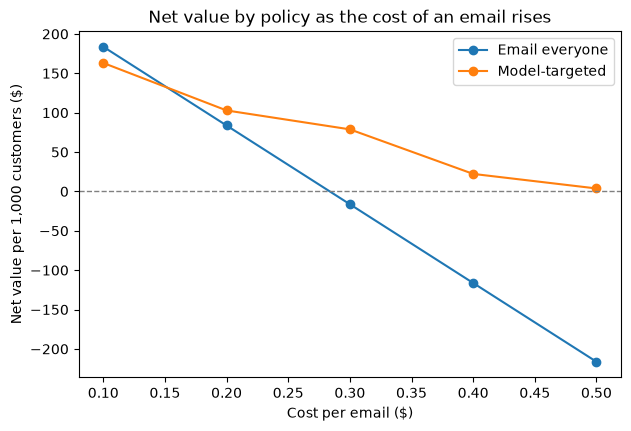

In [6]:
# ==========================================
# Cost Sensitivity Curve
# ==========================================
import matplotlib.pyplot as plt

sw = pd.DataFrame(sweep)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sw['cost_per_email'], sw['everyone_$per1000'], marker='o', label='Email everyone')
ax.plot(sw['cost_per_email'], sw['targeted_$per1000'], marker='o', label='Model-targeted')
ax.axhline(0, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('Cost per email ($)')
ax.set_ylabel('Net value per 1,000 customers ($)')
ax.set_title('Net value by policy as the cost of an email rises')
ax.legend()
plt.show()


**Cost sensitivity.** Emailing everyone earns a positive net value up to about $0.28 per email (3.59pp x $7.90) and loses money beyond that: -$16 per 1,000 customers at $0.30, -$116 at $0.40 and -$216 at $0.50. The model-targeted policy stays non-negative at every cost tested (+$79, +$22 and +$4 per 1,000 at $0.30, $0.40 and $0.50). Targeting does not beat emailing everyone at $0.10 or $0.20, where the intervals include zero. It beats it clearly from $0.30 up, where the interval for the difference excludes zero (+$95 per 1,000 customers, CI +$36 to +$151, at $0.30, rising to +$220, CI +$156 to +$288, at $0.50). At the highest costs the targeted policy is only about break-even (+$4 per 1,000 at $0.50), so what the model buys there is protection from losses, not extra profit.

These figures are in revenue terms. Applying a gross margin m is equivalent to dividing the email cost by m, so a $0.10 email at a 33% margin behaves like the $0.30 row, and at a 20% margin like the $0.50 row.

**Recommendation.** At the assumed $0.10 cost, with no margin adjustment, email everyone: the model-targeted policy does no better (-$21 per 1,000 customers, CI -$69 to +$25). If the margin on an incremental sale is below roughly a third, or the cost per email is above about $0.30, switch to model-targeted emailing. A rank-based cutoff (top k%) might do better than the predicted-uplift threshold used here, but that was not tested. Limitations: this is a single 12,808-customer test split whose overall lift (3.59pp) is below the full-sample 4.52pp, so the crossover cost would sit higher on the full data; the winning model was chosen on this same test set; and an incremental visit is assumed to be worth the average visitor's spend.